# 7) Autoencoder w rozpoznawaniu obrazów

### 1) wczytanie emoji

In [1]:
import os
import cv2
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE

from keras import layers, models

os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

IMG_SIZE = 16

In [2]:
def load_emojis(folder_name="emojis"):
    script_dir = globals()['_dh'][0]
    script_dir = os.path.join(script_dir, "..")
    folder_path = os.path.join(script_dir, folder_name)
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Nie znaleziono folderu z emoji: {folder_path}")

    emojis = {}
    for filename in sorted(os.listdir(folder_path)):
        if filename.lower().endswith(".png"):
            emoji_name = os.path.splitext(filename)[0]
            emoji_path = os.path.join(folder_path, filename)
            emoji_image = cv2.imread(emoji_path, cv2.IMREAD_UNCHANGED)
            if emoji_image is None:
                raise OSError(f"Nie można wczytać obrazu emoji: {emoji_path}")

            emoji_gray = cv2.cvtColor(emoji_image[:, :, :3], cv2.COLOR_BGR2GRAY)

            alpha = emoji_image[:, :, 3].astype(np.float32) / 255.0
            emoji_gray = emoji_gray.astype(np.float32) / 255.0
            emojis[emoji_name] = (emoji_gray * alpha + (1.0 - alpha))

    if not emojis:
        raise ValueError(f"Folder nie zawiera plików PNG z emoji: {folder_path}")

    return emojis

emojis = load_emojis()

### 2) augmentacja danych

In [3]:
# rozszerzamy bazę danych przez lekkie przekształcenia geometryczne i szum,
# żeby sieć neuronowa miała wystarczająco dużo próbek do treningu
# zmniejszamy również obrazy do 16x16

def augment_dataset(emojis_dict, num_augmentations=30):
    X_augmented = []
    names = list(emojis_dict.keys())
    h, w = IMG_SIZE, IMG_SIZE

    for name in names:
        base_img = cv2.resize(emojis_dict[name], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        X_augmented.append(base_img)  # oryginał też dodajemy do zbioru

        for _ in range(num_augmentations):
            # losowy obrót (-10 do 10 stopni) i skala (0.9 do 1.1)
            angle = np.random.uniform(-10, 10)
            scale = np.random.uniform(0.9, 1.1)
            M_rot = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)

            # delikatne przesunięcie (-1 do 1 piksela)
            M_rot[0, 2] += np.random.uniform(-1.0, 1.0)
            M_rot[1, 2] += np.random.uniform(-1.0, 1.0)

            aug_img = cv2.warpAffine(
                base_img, M_rot, (w, h),
                borderMode=cv2.BORDER_CONSTANT, borderValue=1.0
            )

            # drobny szum gaussowski
            noise = np.random.normal(0, 0.02, aug_img.shape).astype(np.float32)
            aug_img = np.clip(aug_img + noise, 0.0, 1.0)

            X_augmented.append(aug_img)

    X_augmented = np.array(X_augmented, dtype=np.float32)
    X_augmented = np.expand_dims(X_augmented, axis=-1)
    return X_augmented

np.random.seed(42)
X_train = augment_dataset(emojis, num_augmentations=40)
np.random.shuffle(X_train)
print(f"Rozmiar rozszerzonego zbioru treningowego: {X_train.shape}")


Rozmiar rozszerzonego zbioru treningowego: (574, 16, 16, 1)


### 3) budowa autoenkodera

In [4]:
def build_autoencoder(img_size=IMG_SIZE):
    input_img = layers.Input(shape=(img_size, img_size, 1))

    # ENKODER

    x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(input_img)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)

    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)

    encoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same', name='encoded_map')(x)  # mapa 8x8x1

    # DEKODER

    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(encoded)
    x = layers.UpSampling2D((2, 2))(x)

    x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = layers.UpSampling2D((2, 2))(x)
    
    decoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    autoencoder = models.Model(input_img, decoded, name="autoencoder")
    encoder = models.Model(input_img, encoded, name="encoder")

    autoencoder.compile(optimizer='adam', loss='mse')
    return autoencoder, encoder

autoencoder, encoder = build_autoencoder(IMG_SIZE)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16, 16, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoded_map (Conv2D)            │ (None, 4, 4, 1)        │           289 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,178 (39.76 KB)

 Trainable params: 10,178 (39.76 KB)

 Non-trainable params: 0 (0.00 B)

### 4) uczenie modelu

In [5]:
history = autoencoder.fit(
    X_train, X_train,
    epochs=200,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.1559 - val_loss: 0.1394
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1204 - val_loss: 0.0839
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0680 - val_loss: 0.0551
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0556 - val_loss: 0.0516
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0527 - val_loss: 0.0498
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0513 - val_loss: 0.0489
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0506 - val_loss: 0.0485
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0503 - val_loss: 0.0482
Epoch 9/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0501 - val_loss: 0.0481
Epoch 10/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0499 - val_loss: 0.0480
Epoch 11/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0498 - val_loss: 0.0479
Epoch 12/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0498 - val_lo

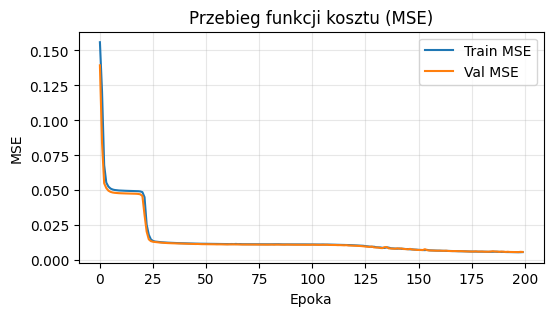

In [6]:
plt.figure(figsize=(6, 3))
plt.plot(history.history['loss'], label='Train MSE')
plt.plot(history.history['val_loss'], label='Val MSE')
plt.title('Przebieg funkcji kosztu (MSE)')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5) porównanie oryginały oraz rekonstrukcji

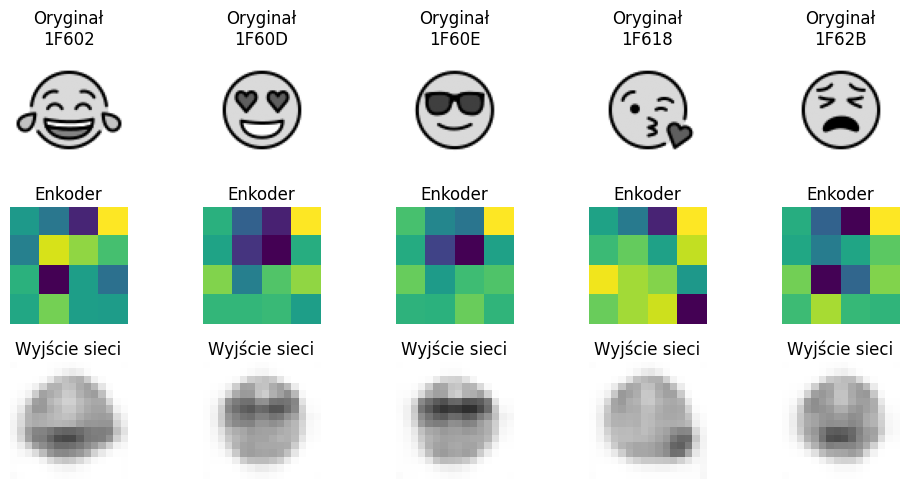

In [7]:
names = list(emojis.keys())

X_resized = []
for n in names:
    X_resized.append(cv2.resize(emojis[n], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
X_base_resized = np.expand_dims(np.array(X_resized), axis=-1)

encoded_maps = encoder.predict(X_base_resized, verbose=0)
reconstructed_imgs = autoencoder.predict(X_base_resized, verbose=0)

n_show = min(5, len(names))
plt.figure(figsize=(10, 5))
for i in range(n_show):
    # Oryginał w oryginalnym rozmiarze
    plt.subplot(3, n_show, i + 1)
    plt.imshow(emojis[names[i]], cmap='gray', vmin=0, vmax=1)
    plt.title(f"Oryginał\n{names[i]}")
    plt.axis('off')

    # Mapa cech z enkodera
    plt.subplot(3, n_show, i + 1 + n_show)
    plt.imshow(encoded_maps[i].squeeze(), cmap='viridis')
    plt.title("Enkoder")
    plt.axis('off')

    # Rekonstrukcja
    plt.subplot(3, n_show, i + 1 + 2 * n_show)
    plt.imshow(reconstructed_imgs[i].squeeze(), cmap='gray', vmin=0, vmax=1)
    plt.title("Wyjście sieci")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 6) wyciągnięcie features z enkodowanego obrazu

In [8]:
def prepare_all_features_ae(emojis_dict, encoder_model):
    names = list(emojis_dict.keys())

    resized_imgs = []
    for n in names:
        img_resized = cv2.resize(emojis_dict[n], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        resized_imgs.append(img_resized)
        
    imgs = np.expand_dims(np.array(resized_imgs), axis=-1)
    
    # wydobycie map cech przez wytrenowany enkoder
    encoded = encoder_model.predict(imgs, verbose=0)
    
    # spłaszczenie do wektorów cech
    X_features = encoded.reshape(len(names), -1)
    return names, X_features

names, X_ae = prepare_all_features_ae(emojis, encoder)


### 7) wizualizacja t-SNE

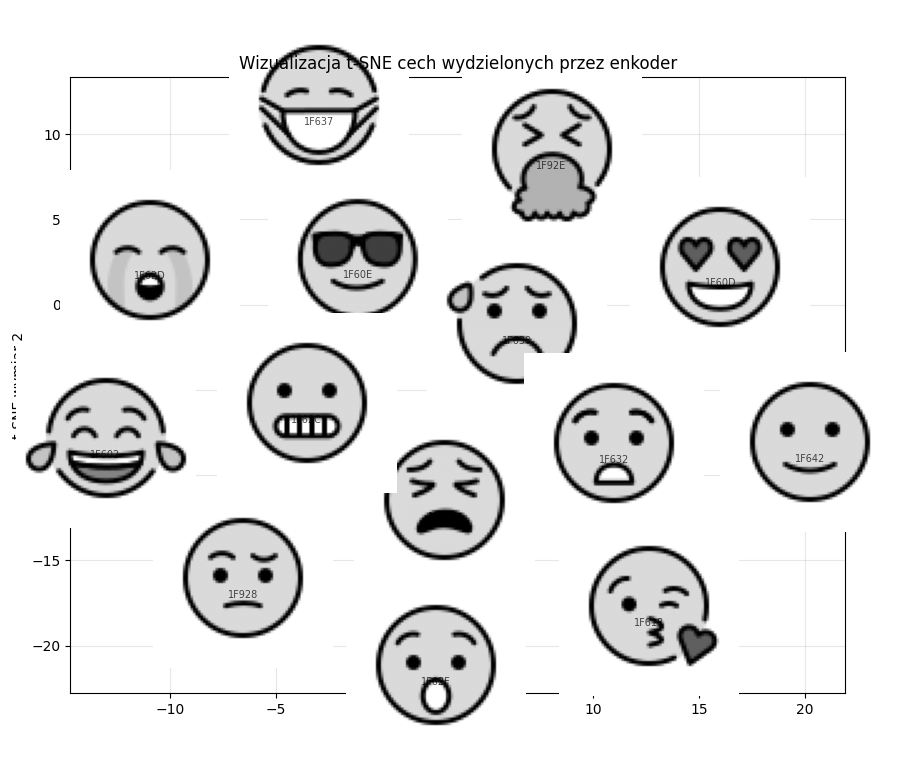

In [9]:
perplexity_val = min(15, max(2, len(names) - 1))
tsne = TSNE(n_components=2, perplexity=perplexity_val, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_ae)

# wizualizacja t-SNE z nałożonymi obrazkami emoji
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], alpha=0.0)

for i, name in enumerate(names):
    img = emojis[name]
    imagebox = OffsetImage(img, cmap='gray', zoom=1.8)
    ab = AnnotationBbox(imagebox, (X_tsne[i, 0], X_tsne[i, 1]), frameon=False)
    ax.add_artist(ab)
    ax.annotate(name, (X_tsne[i, 0], X_tsne[i, 1]), fontsize=7, alpha=0.7, xytext=(0, -14), textcoords='offset points', ha='center')

plt.title("Wizualizacja t-SNE cech wydzielonych przez enkoder")
plt.xlabel("t-SNE wymiar 1")
plt.ylabel("t-SNE wymiar 2")
plt.grid(True, alpha=0.3)
plt.show()

### 8) wyciągnięcie najbliższego sąsiada za pomocą kNN

In [10]:
def retrieve_best_match_ae(query_name, emojis_dict, encoder_model):
    names, X_ae = prepare_all_features_ae(emojis_dict, encoder_model)
    query_idx = names.index(query_name)
    
    # baza danych to wszystko oprócz query
    db_names = [n for i, n in enumerate(names) if i != query_idx]
    X_db = np.delete(X_ae, query_idx, axis=0)
    X_query = X_ae[query_idx].reshape(1, -1)
    
    # znajdujemy najbliższego sąsiada w przestrzeni cech autoenkodera
    knn = NearestNeighbors(n_neighbors=1, metric='euclidean')
    knn.fit(X_db)
    distances, indices = knn.kneighbors(X_query)
    
    best_match = db_names[indices[0][0]]
    best_dist = distances[0][0]
    
    return best_match, best_dist


### 9) przedstawienie wyników

In [11]:
def show_results(query_name, emojis_dict, encoder_model, no_print=False):
    if not no_print:
        print(f"Szukany wzorzec: {query_name}")
        print("-" * 50)

    best_name, best_dist = retrieve_best_match_ae(query_name, emojis_dict, encoder_model)

    if not no_print:
        print(f"Metoda: Autoenkoder | Najlepsze dopasowanie: {best_name} (Dystans: {best_dist:.4f})")

    plt.figure(figsize=(8, 4))
    
    plt.subplot(1, 2, 1)
    plt.imshow(emojis_dict[query_name], cmap="gray", vmin=0, vmax=1)
    plt.title("Query\n(Wzorzec)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(emojis_dict[best_name], cmap="gray", vmin=0, vmax=1)
    plt.title(f"Autoencoder (1-NN)\n{best_name}\nDist: {best_dist:.2f}")
    plt.axis("off")

    plt.tight_layout()
    plt.suptitle("Image Retrieval - Cechy z Autoenkodera", fontsize=14, y=1.1)
    plt.show()


Szukany wzorzec: 1F602
--------------------------------------------------
Metoda: Autoenkoder | Najlepsze dopasowanie: 1F62C (Dystans: 0.3638)


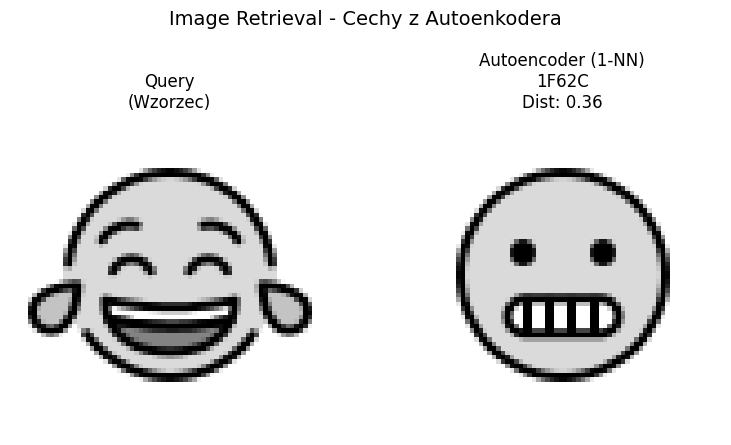

In [12]:
show_results("1F602", emojis, encoder)

Szukany wzorzec: 1F60D
--------------------------------------------------
Metoda: Autoenkoder | Najlepsze dopasowanie: 1F60E (Dystans: 0.2894)


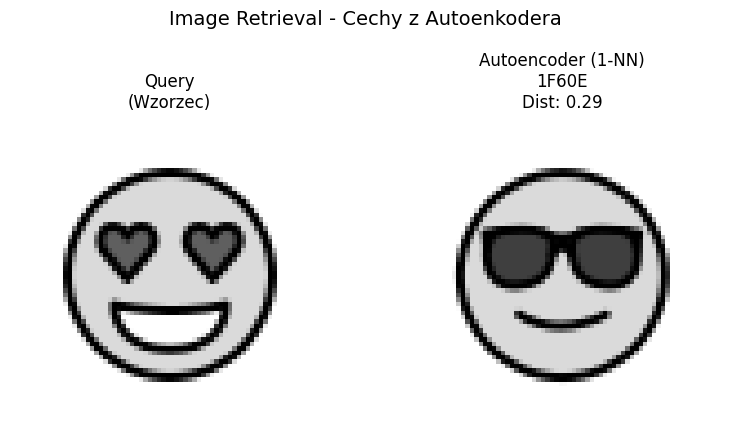

In [13]:
show_results("1F60D", emojis, encoder)

Szukany wzorzec: 1F630
--------------------------------------------------


Metoda: Autoenkoder | Najlepsze dopasowanie: 1F632 (Dystans: 0.2187)


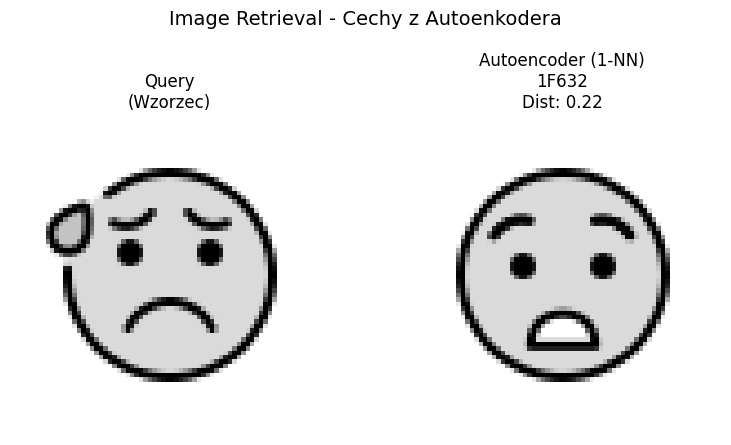

In [14]:
show_results("1F630", emojis, encoder)

**Wnioski:**
 - widać, że autoenkoder radzi sobie lepiej z zachowaniem większości cech emoji (smutne buźki, brwi, zęby, większe coś na oczach)
 - widać też (np. na dekodowanych przykładach), że gubimy szczegóły jak np. łezki czy konkretne długości/obroty ust lub brwi